# Cross-Region Inference Router and Instance Pools for Amazon SageMaker AI

In this notebook, we will show how to use SageMaker AI instance pools and cross-region inference

A deployment can lose capacity in two ways: the instance type you want isn't available, or a whole Region has a problem. This lab handles both:

- **Cross-Region Inference Router**: one router sends traffic to the same model deployed in two Regions. It prefers the local Region, fails over to the other Region when the local deployment is unhealthy, and fails back when it recovers.

- **Instance pools**: one endpoint lists several instance types in priority order. If the preferred type has no capacity, SageMaker AI provisions the next one instead of failing.

We use the smaller `Qwen/Qwen3-4B` model, which fits on one GPU of any instance type in the pool.

## Setup

In [2]:
%pip install --upgrade --quiet --no-warn-conflicts boto3

Note: you may need to restart the kernel to use updated packages.


This lab works in two Regions, so we create a separate set of clients for each:

- `REGION_HOME`: the Region where the router runs and where traffic is served when everything is healthy
- `REGION_REMOTE`: the failover Region

Change both to the Regions enabled for your account. The router also needs its own two clients: `ir` (control plane) creates and describes routers, and `rt` (runtime) sends requests through them.

In [3]:
import time
import re
import json
import boto3
from botocore.exceptions import ClientError
from IPython.display import display, Markdown, clear_output

#boto_session = boto3.Session()
#region = boto_session.region_name

REGION_HOME = "us-east-2"
REGION_REMOTE = "us-west-2"

sm_home = boto3.client("sagemaker", region_name=REGION_HOME)  # client to intreract with SageMaker
sm_runtime_home = boto3.client("sagemaker-runtime", region_name=REGION_HOME)  # client to intreract with SageMaker Endpoints

sm_remote = boto3.client("sagemaker", region_name=REGION_REMOTE)  # client to intreract with SageMaker
sm_runtime_remote = boto3.client("sagemaker-runtime", region_name=REGION_REMOTE)

rt = boto3.client("sagemaker-inference-router-runtime", region_name=REGION_HOME)

The helper functions take the SageMaker AI client as a parameter, so the same functions work in both Regions. They also treat a deleted resource as finished, which we need when we delete an inference component to simulate a failure.

In [ ]:
def get_sagemaker_role():
    arn = boto3.client("sts").get_caller_identity()["Arn"]
    return re.sub(r"^(.+)sts::(\d+):assumed-role/(.+?)/.*$", r"\1iam::\2:role/\3", arn)


def _is_not_found(err: ClientError) -> bool:
    """True if the error means the SageMaker resource does not exist."""
    error = err.response.get("Error", {})
    code = error.get("Code", "")
    message = error.get("Message", "").lower()
    return (code in ("ResourceNotFound", "ResourceNotFoundException")
            or (code == "ValidationException" and ("could not find" in message or "does not exist" in message)))


def _wait_for_resource(describe_fn, name_key, status_key, label, name, sleep_time=60):
    """
    Poll a SageMaker resource until it leaves 'Creating', 'Updating' or 'Deleting' state.
    Returns the final status, or None if the resource no longer exists.
    """
    progress = ""
    while True:
        try:
            status = describe_fn(**{name_key: name})[status_key]
        except ClientError as e:
            if _is_not_found(e):
                print(f"{label}: '{name}' no longer exists (it was deleted).")
                return None
            raise
        if status not in ("Creating", "Updating", "Deleting"):
            break
        progress += "."
        clear_output(wait=True)
        print(f"Waiting for '{name}': {progress}")
        time.sleep(sleep_time)
    print(f"{label}: '{name}', Status: '{status}'")
    return status


def wait_for_endpoint(client, endpoint_name: str, sleep_time: int = 60):
    return _wait_for_resource(client.describe_endpoint, "EndpointName", "EndpointStatus",
                              "Endpoint", endpoint_name, sleep_time,)


def wait_for_ic(client, ic_name: str, sleep_time: int = 60):
    return _wait_for_resource(client.describe_inference_component, "InferenceComponentName", "InferenceComponentStatus",
                              "IC", ic_name, sleep_time,)

In [ ]:
#
# Overwrite with your role ARN if you are running this notebook outside of SageMaker Studio
#
role = None

if role == None:
    role = get_sagemaker_role()
print(role)

## Deploy models and cross-region router

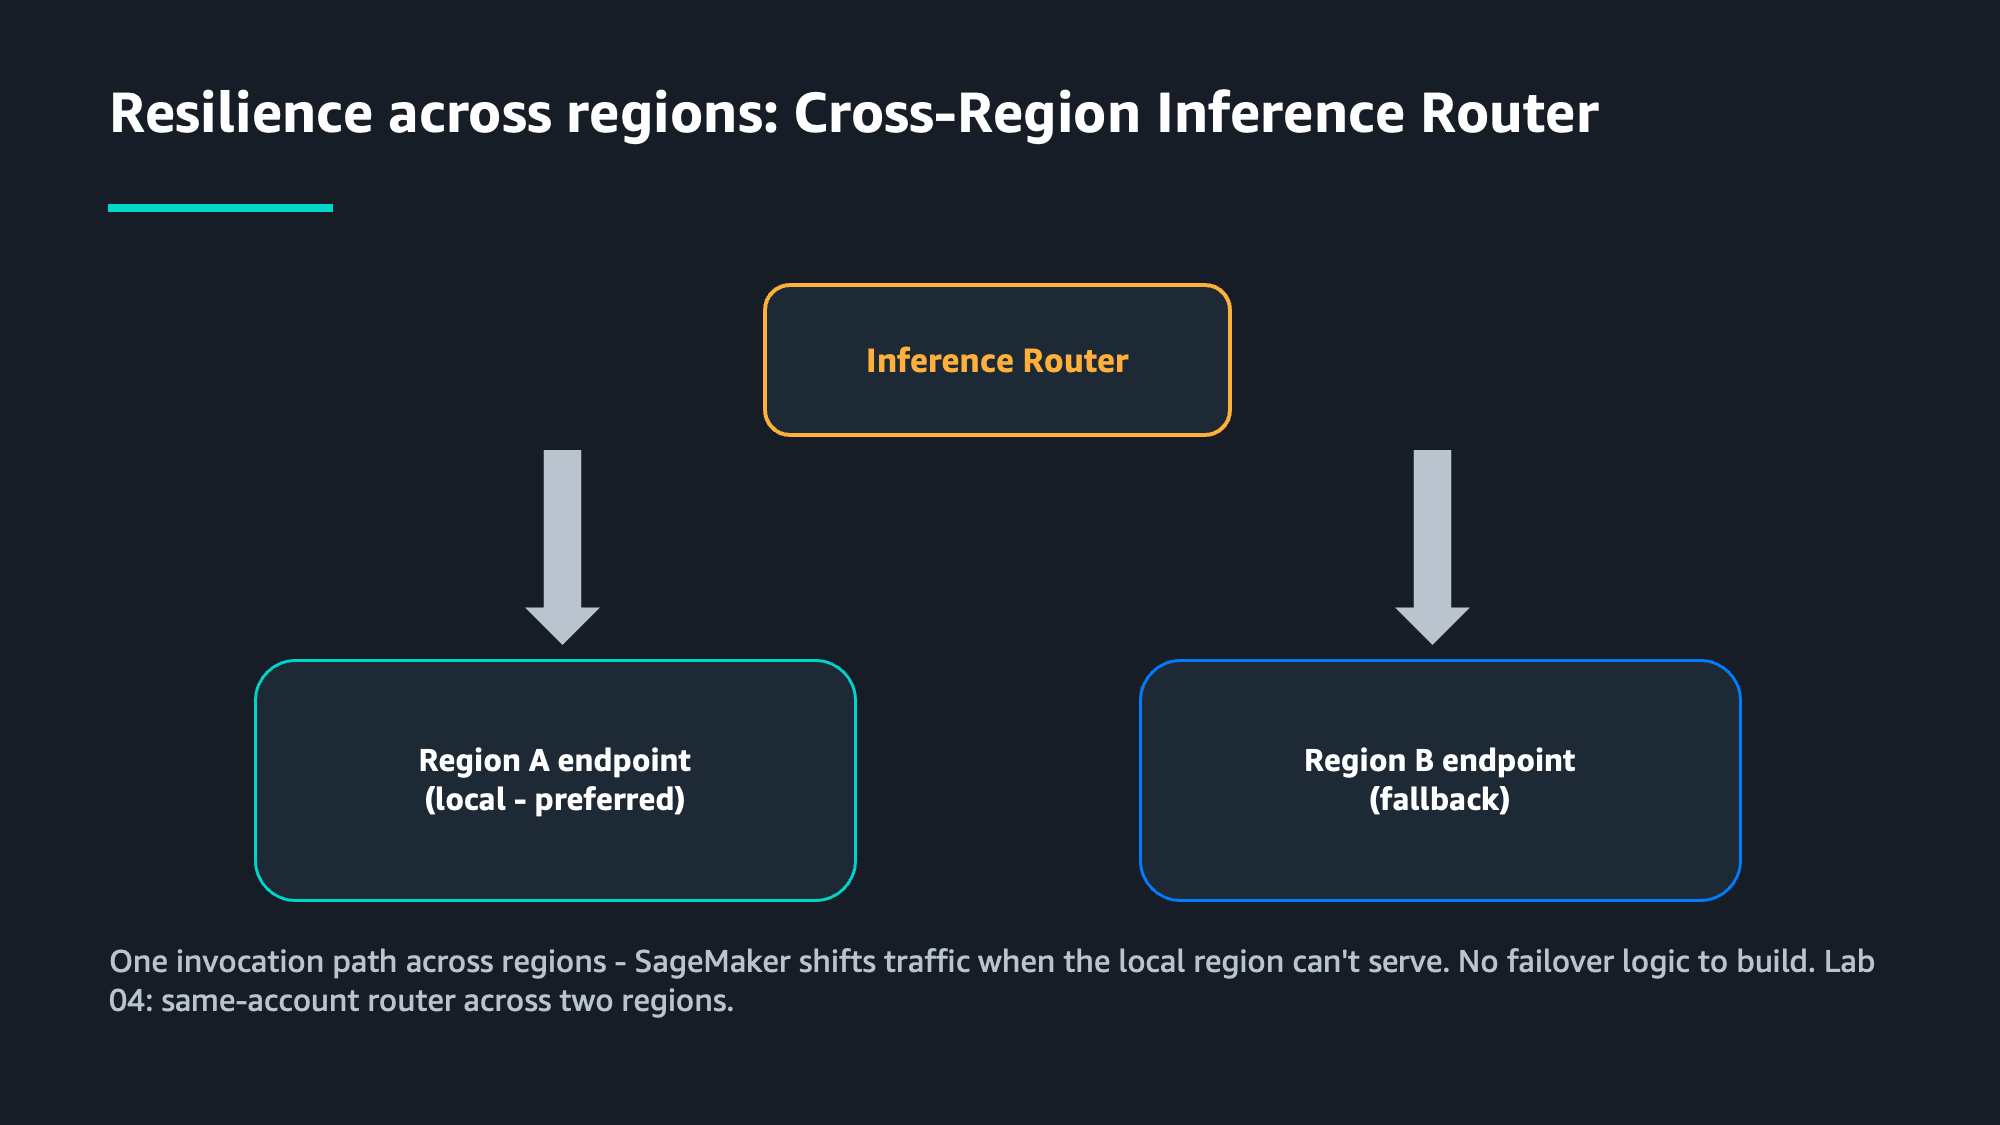

### Step 1: Create the model in both Regions

We use the same model name and environment in both Regions. The model has 4B parameters, so it runs on one GPU (`SM_VLLM_TENSOR_PARALLEL_SIZE: 1`). We use a 16k context and up to 32 concurrent sequences.

In [6]:
model_id = "Qwen/Qwen3-4B"
model_name = f"model-{time.strftime('%y%m%d-%H%M%S')}"
endpoint_name = model_name
endpoint_config_name = model_name
timeout = 600
variant_name = "v1"

In [ ]:
env = {
    "SM_VLLM_MODEL": model_id,
    "SM_VLLM_TENSOR_PARALLEL_SIZE": "1",
    "SM_VLLM_MAX_MODEL_LEN": "16384",
    "SM_VLLM_MAX_NUM_SEQS": "32",
    "SM_VLLM_REASONING_PARSER": "qwen3",
}

reg_list = [(REGION_HOME, sm_home), (REGION_REMOTE, sm_remote)]

Each Region pulls the vLLM DLC image from its own Amazon ECR registry, so the image URI is built per Region.

In [8]:
for loc in reg_list:
    inference_image = f"763104351884.dkr.ecr.{loc[0]}.amazonaws.com/vllm:0.31.0-gpu-py312-cu130-ubuntu24.04-sagemaker"

    _ = loc[1].create_model(
        ModelName=model_name,
        ExecutionRoleArn=role,
        PrimaryContainer={
            "Image": inference_image,
            "Environment": env,
        },
    )

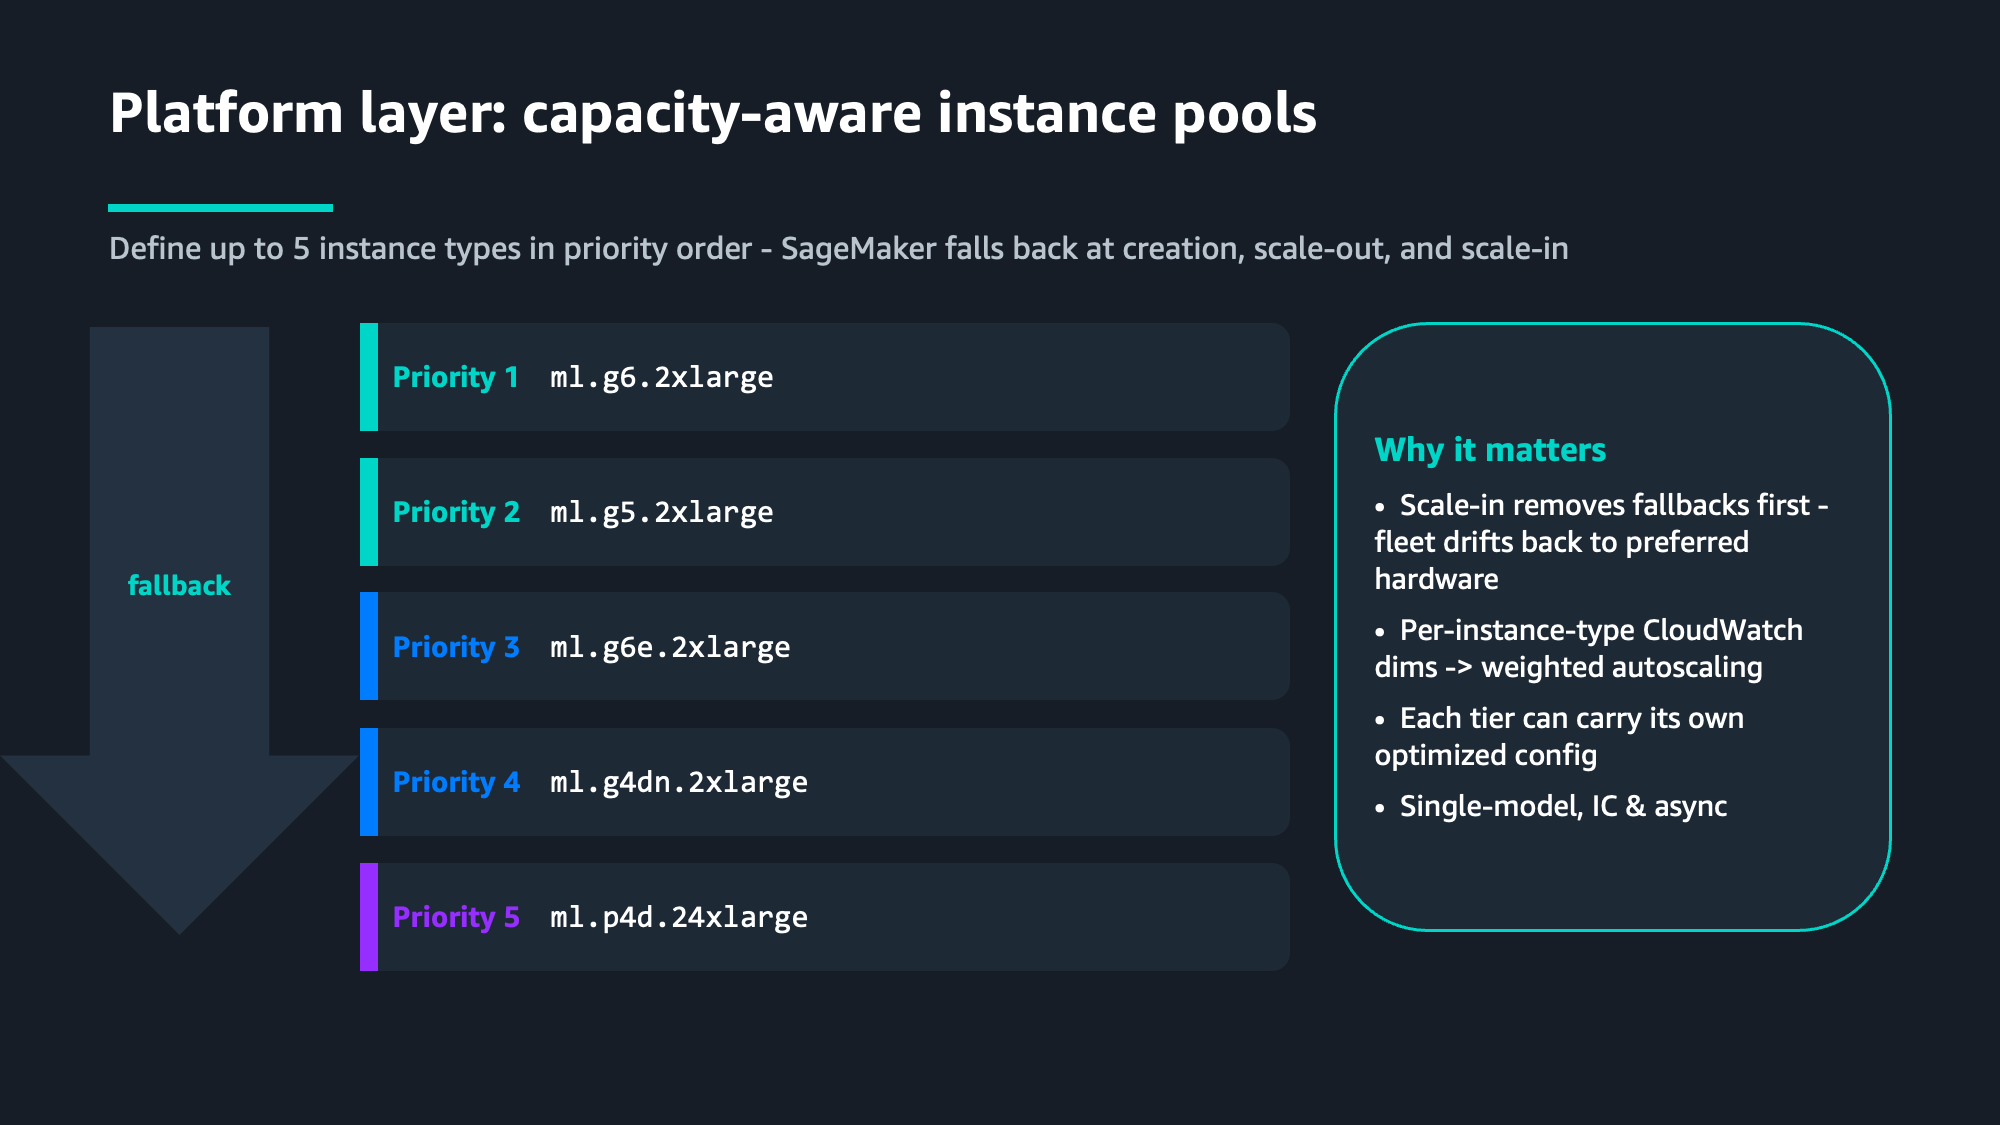

### Step 2: Create endpoints with instance pools

Instead of `InstanceType`, the production variant lists `InstancePools`, each with a `Priority` (1 is the most preferred). SageMaker AI tries the pools in order and uses the first type with available capacity. `VariantInstanceProvisionTimeoutInSeconds` limits how long it waits on one type before moving to the next.

Every type in the list must be able to run the model. All five types here have at least one GPU with enough memory for Qwen3-4B.

In [9]:
instance_pools = [
    { "InstanceType": "ml.g6.2xlarge", "Priority": 1 },
    { "InstanceType": "ml.g5.2xlarge", "Priority": 2 },
    { "InstanceType": "ml.g6.xlarge", "Priority": 3 },
    { "InstanceType": "ml.g5.xlarge", "Priority": 4 },
    { "InstanceType": "ml.g7.2xlarge", "Priority": 5 },
]

for client in [sm_home, sm_remote]:
    _ = client.create_endpoint_config(
        EndpointConfigName=endpoint_config_name,
        ExecutionRoleArn=role,
        ProductionVariants=[
            {
                "VariantName": variant_name,
                "InitialInstanceCount": 1,
                "ContainerStartupHealthCheckTimeoutInSeconds": timeout,
                "VariantInstanceProvisionTimeoutInSeconds": timeout,
                "InstancePools": instance_pools,
                "InferenceAmiVersion": "al2023-ami-sagemaker-inference-gpu-4-1",
            },
        ],
    )
    _ = client.create_endpoint(EndpointName=endpoint_name,
                               EndpointConfigName=endpoint_config_name)

Wait for both endpoints, then check which instance type each Region provisioned. The result depends on available capacity and your service quotas, so it can differ between Regions and between runs.

In [10]:
for client in [sm_home, sm_remote]:
    _ = wait_for_endpoint(client, endpoint_name)
    endpoint_info = client.describe_endpoint(EndpointName=endpoint_name)
    print(f"{json.dumps(endpoint_info.pop("ProductionVariants", None)[0]["InstancePools"], indent=2, default=str)}")

Waiting for 'model-261103-200319': ....
Endpoint: 'model-261103-200319', Status: 'InService'
[
  {
    "InstanceType": "ml.g7.2xlarge",
    "CurrentInstanceCount": 1
  }
]
Endpoint: 'model-261103-200319', Status: 'InService'
[
  {
    "InstanceType": "ml.g7.2xlarge",
    "CurrentInstanceCount": 1
  }
]


### Step 3: Deploy the inference components

Create one inference component in each Region, named `ic-<region>`. Each one uses one GPU.

In [ ]:
compute_req = {
    "MinMemoryRequiredInMb": 1024,
    "NumberOfAcceleratorDevicesRequired": 1,
}

for loc in reg_list:
    ic_name = f"ic-{loc[0]}"
    _ = loc[1].create_inference_component(
        InferenceComponentName=ic_name,
        EndpointName=endpoint_name,
        VariantName=variant_name,
        Specification={
            "ModelName": model_name,
            "StartupParameters": {
                "ModelDataDownloadTimeoutInSeconds": timeout,
                "ContainerStartupHealthCheckTimeoutInSeconds": timeout,
            },
            "ComputeResourceRequirements": compute_req,

        },
        RuntimeConfig={
            "CopyCount": 1,
        },
    )

In [ ]:
for loc in reg_list:
    _ = wait_for_ic(loc[1], f"ic-{loc[0]}")

In [13]:
#
# Helper function
#
def invoke_endpoint(client, payload, endpoint_name, inference_component, reasoning_tag="reasoning"):
    start_time = time.time()
    res = client.invoke_endpoint(EndpointName=endpoint_name,
                                 InferenceComponentName=inference_component,
                                 Body=json.dumps(payload),
                                 ContentType="application/json")
    response = json.loads(res["Body"].read().decode("utf8"))
    end_time = time.time()

    print(f"✅ Response time: {end_time-start_time:.2f}s\n")

    output = ""
    reasoning = response["choices"][0]["message"].get(reasoning_tag, None)
    if reasoning:
        output += f"### Reasoning:\n---\n{reasoning}\n\n"

    content = response["choices"][0]["message"].get("content", None)
    if content:
        output += f"### Content:\n---\n{content}\n\n---"

    display(Markdown(output))

    return response

Send a test request directly to the remote Region endpoint, to check that the model works there before we put the router in front of it.

In [14]:
payload={
    "messages": [
        {"role": "user", "content": "Who are you?"}
    ],
}
_ = invoke_endpoint(sm_runtime_remote, payload, endpoint_name, f"ic-{REGION_REMOTE}")

✅ Response time: 2.28s



### Reasoning:
---

Okay, the user is asking, "Who are you?" I need to respond appropriately. First, I should introduce myself clearly. I'm Qwen, a large-scale language model developed by Alibaba Cloud. I should mention my capabilities, like answering questions, creating content, and assisting with tasks. Also, I should highlight my multilingual support and the fact that I'm designed to be helpful and friendly. I should keep the tone positive and open for further questions. Let me make sure the response is concise and covers all the key points without being too technical.


### Content:
---


Hello! I am Qwen, a large-scale language model developed by Alibaba Cloud. I can answer questions, create content, and assist with various tasks. I support multiple languages and am designed to be helpful and friendly. How can I assist you today? 😊

---

### Step 4: Create the cross-Region Inference Router

The router routes to inference component ARNs, so we look up the ARN in each Region.

In [ ]:
res = sm_home.describe_inference_component(InferenceComponentName=f"ic-{REGION_HOME}")
print(res['InferenceComponentArn'])
resource_1 = res['InferenceComponentArn']

In [ ]:
res = sm_remote.describe_inference_component(InferenceComponentName=f"ic-{REGION_REMOTE}")
print(res['InferenceComponentArn'])
resource_2 = res['InferenceComponentArn']

A router has one or more **routing targets**. Each target is a logical model name (`my-model`) with a list of **destinations**, which are the inference component ARNs. Clients call the router with the target name and never see which Region serves the request.

In [ ]:
response = sm_home.create_inference_router(
    InferenceRouterName="my-router",
    RoutingTargets=[
        {
            "Name": "my-model",
            "Destinations": [
                {"ResourceArn": resource_1},
                {"ResourceArn": resource_2},
            ],
        }
    ],
)
print(response["InferenceRouterArn"])

Check the routing status of each destination. Both should be `Routable`. If a destination is still `Unroutable`, wait a minute and run the cell again.

In [ ]:
desc = sm_home.describe_inference_router(InferenceRouterName="my-router")
for target in desc["RoutingTargets"]:
    for dest in target["Destinations"]:
        print(target["Name"], dest["ResourceArn"], dest["RoutingStatus"])

Send a request through the router. The response shows which destination served it and why. With both Regions healthy, the home Region serves it with reason `local-preferred`.

In [ ]:
resp = rt.invoke_inference_router(
    InferenceRouterName="my-router",
    RoutingTargetName="my-model",
    ContentType="application/json",
    Body=json.dumps(payload),
)

print("Served by:", resp["InvokedRoutedResourceArn"])
print("Reason:   ", resp["RoutingReason"])
#print("Output:   ", resp["Body"].read().decode())

### Step 5: Simulate a Regional failure (failover)

Delete the home Region inference component to simulate the home Region becoming unavailable. The cell waits until the deletion finishes.

In [20]:
_ = sm_home.delete_inference_component(InferenceComponentName=f"ic-{REGION_HOME}")
_ = wait_for_ic(sm_home, f"ic-{REGION_HOME}")

Waiting for 'ic-us-east-2': ...
IC: 'ic-us-east-2' no longer exists (it was deleted).


The router now marks the home destination `Unroutable`.

In [ ]:
desc = sm_home.describe_inference_router(InferenceRouterName="my-router")
for target in desc["RoutingTargets"]:
    for dest in target["Destinations"]:
        print(target["Name"], dest["ResourceArn"], dest["RoutingStatus"])

Send the same request again. The remote Region now serves it with reason `only-healthy`. The client calls the same router and target, with no code change.

In [ ]:
resp = rt.invoke_inference_router(
    InferenceRouterName="my-router",
    RoutingTargetName="my-model",
    ContentType="application/json",
    Body=json.dumps(payload),
)

print("Served by:", resp["InvokedRoutedResourceArn"])
print("Reason:   ", resp["RoutingReason"])
#print("Output:   ", resp["Body"].read().decode())

### Step 6: Recover the home Region (failback)

Recreate the home Region inference component and wait until it is `InService`.

In [23]:
ic_name = f"ic-{REGION_HOME}"
_ = sm_home.create_inference_component(
    InferenceComponentName=ic_name,
    EndpointName=endpoint_name,
    VariantName=variant_name,
    Specification={
        "ModelName": model_name,
        "StartupParameters": {
            "ModelDataDownloadTimeoutInSeconds": timeout,
            "ContainerStartupHealthCheckTimeoutInSeconds": timeout,
        },
        "ComputeResourceRequirements": compute_req,

    },
    RuntimeConfig={
        "CopyCount": 1,
    },
)
_ = wait_for_ic(sm_home, f"ic-{REGION_HOME}")

Waiting for 'ic-us-east-2': ........
IC: 'ic-us-east-2', Status: 'InService'


Both destinations should be `Routable` again.

In [ ]:
desc = sm_home.describe_inference_router(InferenceRouterName="my-router")
for target in desc["RoutingTargets"]:
    for dest in target["Destinations"]:
        print(target["Name"], dest["ResourceArn"], dest["RoutingStatus"])

Send a request. Once the router sees the home destination as healthy again, traffic returns to the home Region with reason `local-preferred`. This can take a few minutes after the inference component is `InService`. If the remote Region still serves the request, wait and run the cell again.

In [ ]:
resp = rt.invoke_inference_router(
    InferenceRouterName="my-router",
    RoutingTargetName="my-model",
    ContentType="application/json",
    Body=json.dumps(payload),
)

print("Served by:", resp["InvokedRoutedResourceArn"])
print("Reason:   ", resp["RoutingReason"])
#print("Output:   ", resp["Body"].read().decode())

## Cleanup

Delete the router first, then the inference components, endpoints, endpoint configurations and models in both Regions.

In [26]:
CLEANUP = True

In [27]:
if CLEANUP:
    sm_home.delete_inference_router(InferenceRouterName="my-router")

In [28]:
if CLEANUP:
    _ = sm_remote.delete_inference_component(InferenceComponentName=f"ic-{REGION_REMOTE}")
    _ = sm_remote.delete_endpoint(EndpointName=endpoint_name)
    _ = sm_remote.delete_endpoint_config(EndpointConfigName=endpoint_config_name)
    _ = sm_remote.delete_model(ModelName=model_name)

In [29]:
if CLEANUP:
    _ = sm_home.delete_inference_component(InferenceComponentName=f"ic-{REGION_HOME}")
    _ = sm_home.delete_endpoint(EndpointName=endpoint_name)
    _ = sm_home.delete_endpoint_config(EndpointConfigName=endpoint_config_name)
    _ = sm_home.delete_model(ModelName=model_name)